# Model benchmark comparison

This notebook reads `out/model_benchmark.json` and compares API and local models independently. It includes charts for accuracy, inference latency, and model size versus accuracy.

Run it from the project root so the benchmark path resolves correctly.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

benchmark_path = Path('out/model_benchmark.json')
with benchmark_path.open(encoding='utf-8') as f:
    models = json.load(f)['models']

groups = {
    provider: sorted(
        [m for m in models if m.get('provider') == provider],
        key=lambda m: m['name'],
    )
    for provider in ('api', 'local')
}

for provider, entries in groups.items():
    print(f'{provider.upper()}: {len(entries)} models')
    for m in entries:
        print(f"  {m['name']}: {m['accuracy_percent']}% accuracy, {m['latency_seconds']} s, {m['parameters_billions']}B parameters")

API: 2 models
  nvidia/nemotron-3-nano-omni-30b-a3b-reasoning:free: 90.48% accuracy, 245.1 s, 30B parameters
  nvidia/nemotron-3.5-super-vl:free: 100.0% accuracy, 65.0 s, 120B parameters
LOCAL: 3 models
  qwen2.5vl:32b: 85.71% accuracy, 519.356 s, 32B parameters
  qwen2.5vl:3b: 47.06% accuracy, 183.658 s, 3B parameters
  qwen2.5vl:7b: 75.0% accuracy, 59.321 s, 7B parameters


## 1. Accuracy by model
Each panel compares models within one provider group.

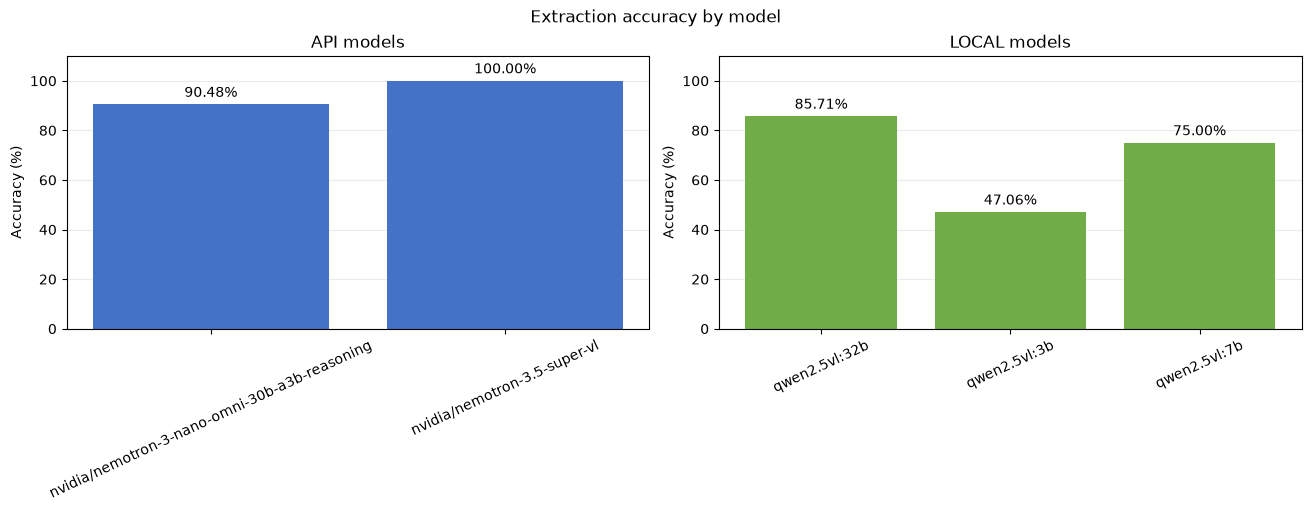

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
colors = {'local': '#4472C4', 'api': '#70AD47'}
for ax, provider in zip(axes, ('api', 'local')):
    entries = groups[provider]
    names = [m['name'].replace(':free', '') for m in entries]
    values = [m['accuracy_percent'] for m in entries]
    bars = ax.bar(names, values, color=colors[provider])
    ax.set_title(f'{provider.upper()} models')
    ax.set_ylabel('Accuracy (%)')
    ax.set_ylim(0, 110)
    ax.bar_label(bars, fmt='%.2f%%', padding=3)
    ax.tick_params(axis='x', labelrotation=25)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)
fig.suptitle('Extraction accuracy by model')
plt.show()

## 2. Inference latency by model
Lower latency is faster. API and local timing are shown in separate panels.

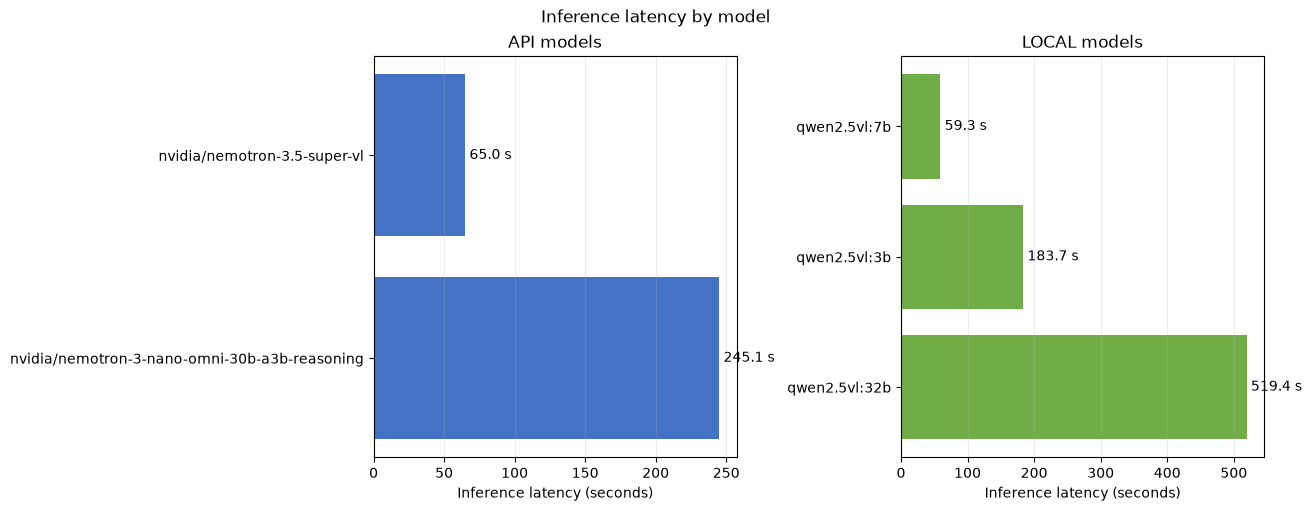

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, provider in zip(axes, ('api', 'local')):
    entries = groups[provider]
    names = [m['name'].replace(':free', '') for m in entries]
    values = [m['latency_seconds'] for m in entries]
    bars = ax.bar(names, values, color=colors[provider])
    ax.set_title(f'{provider.upper()} models')
    ax.set_ylabel('Inference latency (seconds)')
    ax.bar_label(bars, fmt='%.1f s', padding=3)
    ax.tick_params(axis='x', labelrotation=25)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)
fig.suptitle('Inference latency by model')
plt.show()

## 3. Parameter count versus accuracy
Marker labels identify the model; total parameters are used on the x-axis.

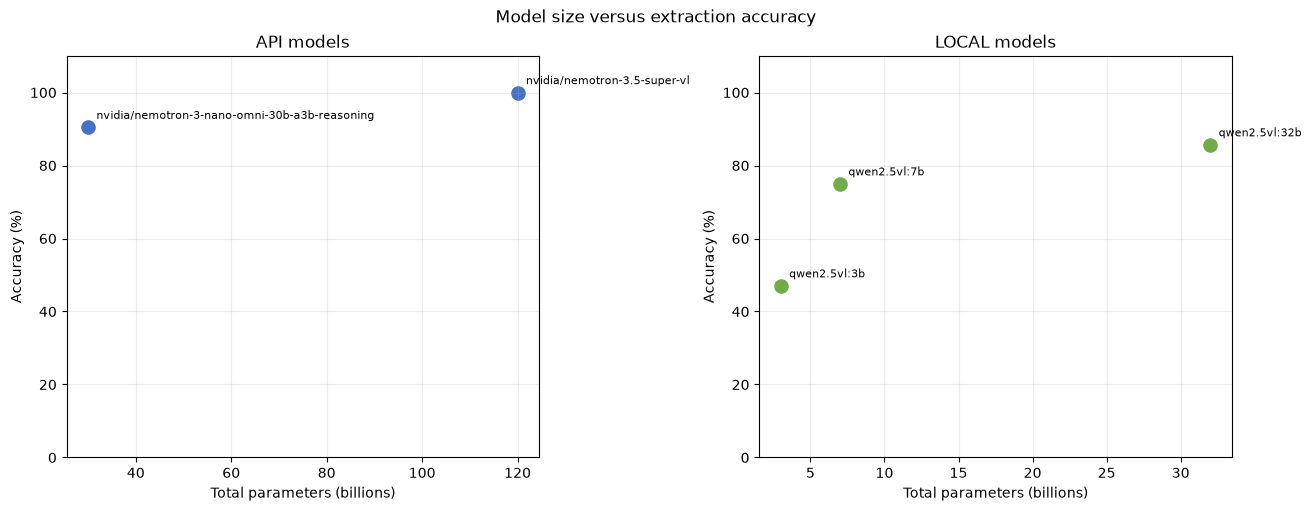

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, provider in zip(axes, ('api', 'local')):
    entries = groups[provider]
    for m in entries:
        x = m['parameters_billions']
        y = m['accuracy_percent']
        ax.scatter(x, y, s=90, color=colors[provider])
        ax.annotate(m['name'].replace(':free', ''), (x, y), xytext=(6, 6), textcoords='offset points', fontsize=8)
    ax.set_title(f'{provider.upper()} models')
    ax.set_xlabel('Total parameters (billions)')
    ax.set_ylabel('Accuracy (%)')
    ax.set_ylim(0, 110)
    ax.grid(alpha=0.25)
fig.suptitle('Model size versus extraction accuracy')
plt.show()

## Notes

- Accuracy comes from the saved benchmark and uses the evaluator's field-level scoring.
- Latency values are the recorded end-to-end inference times in seconds.
- The API and local charts are separated because they run on different infrastructure.
- Parameter count is total model size; for mixture-of-experts API models, active parameter counts are recorded separately in the JSON but are not used in chart 3.